# Dimensionality reduction and anomaly detection

*Session 11, block 2. Course material, licence CC BY 4.0. Sections marked "adapted from" reuse third-party material under the licence named there.*

Tables in practice have many columns, and people can look at two or three at a time. After this block you can reduce many columns to a few with principal component analysis and read its explained variance and loadings, draw two-dimensional maps of high-dimensional data with t-SNE and UMAP without over-reading them, rank unusual rows with Isolation Forest and the local outlier factor (continuing the outliers of Session 4), and test whether clusters and components help a supervised model.

## Overview

| Section | What it covers |
|---|---|
| Principal component analysis: explained variance and loadings | components, scores, explained variance and loadings, eigenvalues by hand, the geometry on two columns, reconstruction error, PCA versus regression, the wine data, scalers and outliers, sparse and one-hot columns, how many components, digits and noise filtering |
| t-SNE and UMAP for visualisation | neighbourhood maps, t-SNE and the perplexity, UMAP and its parameters, trustworthiness on the digits, manifold learning (MDS, LLE, Isomap), what such maps cannot show |
| Worked example · What do Berlin listings offer? PCA of the amenities | amenities as indicator columns, an equipment component, a component that records the data form, a t-SNE map of the listings |
| Model-based anomaly detection: Isolation Forest and local outlier factor | Isolation Forest, local outlier factor, choosing a detector, four detectors on toy data, evaluating with known labels, implausible Berlin listings and a price ratio |
| Clusters and components as features | centroid distances and components inside a pipeline, scaling before PCA in a classifier, location clusters in a price model |
| Check your understanding, Exercises, Debrief | five questions, seven exercises in pairs, what to compare afterwards |

Which method for which goal:

```mermaid
flowchart LR
    G{"Goal?"} -->|"compress, denoise,<br/>features for a model"| PCA["PCA<br/>(linear, reversible)"]
    G -->|"a 2-D picture of<br/>neighbourhoods"| NL["t-SNE or UMAP<br/>(non-linear)"]
    G -->|"unusual rows"| AD["Isolation Forest, LOF,<br/>domain rule"]
    PCA --> F["Features for a<br/>supervised model"]
    AD --> F
```

The first code cell moves to the repository root, where the case-study paths start. Run the cells in order. The Airbnb data must exist in `case-study/data/airbnb/` (download `airbnb.zip` from the course drive and unzip it into `case-study/data/`; see [case-study/README.md](../../../case-study/README.md)); the Telco data are read from GitHub.

In [1]:
# Run the code from the repository root, where the case-study paths start.
import os
from pathlib import Path

os.chdir(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "case-study").is_dir()))

Next the main libraries of the block. `PCA` is in `sklearn.decomposition`, t-SNE in `sklearn.manifold`, the two detectors in `sklearn.ensemble` and `sklearn.neighbors`. Later sections import what else they need where they use it. `DATA` points to the session's `datasets/` folder, which holds two small third-party tables used in the PCA section.

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.manifold import TSNE, trustworthiness
from sklearn.neighbors import LocalOutlierFactor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 12)
DATA = Path("sessions/11-unsupervised-learning/datasets")
plt.rcParams["figure.dpi"] = 72                                # keeps the saved notebook small

## Principal component analysis: explained variance and loadings

**Principal component analysis** (PCA) finds new axes for the data, the **principal components** (PCs). Each PC is a weighted sum of the original columns. The first PC is the direction along which the rows vary most (largest **variance**). The second is the direction of largest remaining variance at right angles to (uncorrelated with) the first, and so on. With p columns there are p components; usually the first few carry most of the variance.

An everyday analogy: photographing a teapot. From one side you see the spout and the handle, from above you see only a circle. PCA picks the camera angle that shows the most spread of the object, then the best second angle, and so on.

Three outputs matter:

- **Scores**: the coordinates of each row on the new axes (`pca.transform`). PC1 and PC2 scores give a 2-D map.
- **Explained variance ratio**: the share of the total variance carried by each PC (`explained_variance_ratio_`). A **scree plot** shows these shares; the cumulative sum tells how many PCs keep, say, 80 %.
- **Loadings**: the weights of the original columns in each PC (`components_`). They say what a component *means*.

A worked example with two standardised columns that have correlation 0.8. Their correlation matrix is [[1, 0.8], [0.8, 1]]. Its **eigenvectors** (directions that the matrix only stretches) are (1, 1)/√2 and (1, −1)/√2, with **eigenvalues** (the stretch factors, here the variances along those directions) 1.8 and 0.2. So PC1 is the average of the two columns and explains 1.8 / 2 = 90 % of the variance; PC2, their difference, explains 10 %. Both loadings on PC1 are 1/√2 ≈ 0.71.

**Predict.** What would the eigenvalues be if the correlation were 0? `np.linalg.eigh` computes eigenvalues and eigenvectors of a symmetric matrix.

In [3]:
eigval, eigvec = np.linalg.eigh(np.array([[1.0, 0.8], [0.8, 1.0]]))
print("eigenvalues:", eigval.round(2), "| PC1 direction:", np.abs(eigvec[:, -1]).round(2))

eigenvalues: [0.2 1.8] | PC1 direction: [0.71 0.71]


### The geometry of PCA on two columns

*Adapted from [Geometric Intuitions of PCA](https://github.com/INRIA/scikit-learn-mooc/blob/main/notebooks/dimred_intuitions.ipynb) (INRIA scikit-learn MOOC, CC BY 4.0).*

PCA is an unsupervised method: it works with features only, there is no target. To build geometric intuition we use a simple 2-D feature space: the Chinstrap penguins of the Palmer penguins data and two correlated features, the length and the depth of the culmen (the upper ridge of the bill). The idea is not to predict one feature from the other, but to measure how much independent information each carries.

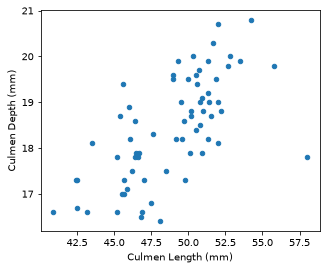

In [4]:
penguins = pd.read_csv(DATA / "penguins_classification.csv")
penguins = penguins[penguins["Species"] == "Chinstrap"].drop(columns="Species")
ax = penguins.plot.scatter(x="Culmen Length (mm)", y="Culmen Depth (mm)", figsize=(5, 4))

PCA finds new features (principal components) that capture the structure of the data. The first PC is the direction along which the data vary most; because the two features are correlated, there is a clear dominant direction. We first extract both components (`n_components` equal to the number of features). **This is not dimensionality reduction yet**: the components are linear combinations of the centred original features, just a change of basis to a more convenient coordinate system.

After fitting, `components_` has shape `(n_components, n_features)`: each row is a PC, each column an original feature. Together with `mean_` it tells how to compute the new features.

In [5]:
pca_p = PCA(n_components=2).fit(penguins)
for i, component in enumerate(pca_p.components_):
    terms = " + ".join(f"{w:.1f} * ({f} - {m:.1f})" for w, f, m in zip(component, penguins.columns, pca_p.mean_))
    print(f"PC{i + 1} = {terms}")

PC1 = 1.0 * (Culmen Length (mm) - 48.8) + 0.2 * (Culmen Depth (mm) - 18.4)
PC2 = -0.2 * (Culmen Length (mm) - 48.8) + 1.0 * (Culmen Depth (mm) - 18.4)


The components are perpendicular to each other and work as new coordinate axes. We draw them from the centre of the cloud.

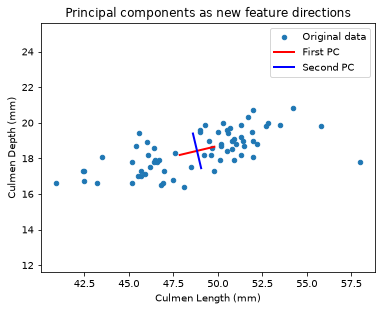

In [6]:
fig, ax = plt.subplots(figsize=(6, 4.5))
penguins.plot.scatter(x="Culmen Length (mm)", y="Culmen Depth (mm)", label="Original data", ax=ax)
center = pca_p.mean_
for component, color, label in zip(pca_p.components_, ["red", "blue"], ["First PC", "Second PC"]):
    endpoints = np.array([center - component, center + component])
    ax.plot(endpoints[:, 0], endpoints[:, 1], color=color, linewidth=2, label=label)
ax.legend()
ax.axis("equal")
ax.set_title("Principal components as new feature directions")
plt.show()

The red line, the first PC, follows the correlation pattern; the blue line is perpendicular and captures the remaining variance. `explained_variance_` is the ordinary variance of the data in the new coordinates, which we can check by projecting the centred data onto the components (`ddof=1` divides by n − 1). Its square root is a standard deviation, here still in millimetres because both features share that unit; in general PCA mixes units and only the *ratio* is interpretable.

In [7]:
print("explained_variance_:", pca_p.explained_variance_.round(3))
print("variance of projected data:", ((penguins.values - pca_p.mean_) @ pca_p.components_.T).var(axis=0, ddof=1).round(3))
print("std along PCs (mm):", np.sqrt(pca_p.explained_variance_).round(3))
print("explained_variance_ratio_:", pca_p.explained_variance_ratio_.round(3))

explained_variance_: [11.738  0.702]
variance of projected data: [11.738  0.702]
std along PCs (mm): [3.426 0.838]
explained_variance_ratio_: [0.944 0.056]


#### From two dimensions to one: the reconstruction error

Keeping only the first component represents each penguin by one number. This works because the two features are correlated: one degree of freedom, the overall size of the bill, captures most of the information. Samples that were close in 2-D remain close in 1-D.

When we use fewer components than features, we lose information. `inverse_transform` maps the 1-D scores back into the 2-D space: the reconstructed points all lie on a line, because the variance perpendicular to it was discarded. A natural measure of the loss is the **mean squared reconstruction error**: the squared Euclidean distance between each row and its reconstruction (summed over features with `axis=1`), averaged over rows.

shape (68, 2) -> (68, 1) | variance kept: 94%
mean squared reconstruction error: 0.6912


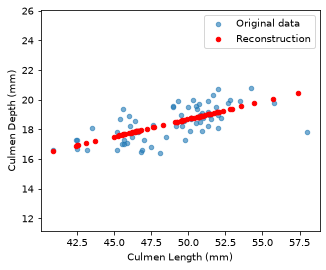

In [8]:
pca_1d = PCA(n_components=1)
scores_1d = pca_1d.fit_transform(penguins)
reconstructed = pca_1d.inverse_transform(scores_1d)
print("shape", penguins.shape, "->", scores_1d.shape, f"| variance kept: {pca_1d.explained_variance_ratio_[0]:.0%}")
print("mean squared reconstruction error:", round(np.mean(np.sum((penguins.values - reconstructed) ** 2, axis=1)), 4))

fig, ax = plt.subplots(figsize=(5, 4))
penguins.plot.scatter(x="Culmen Length (mm)", y="Culmen Depth (mm)", alpha=0.6, label="Original data", ax=ax)
ax.scatter(reconstructed[:, 0], reconstructed[:, 1], color="red", s=20, label="Reconstruction")
ax.axis("equal")
ax.legend()
plt.show()

#### PCA versus linear regression

Both draw a line through the cloud, but not the same line. Linear regression of depth on length minimises the *vertical* distances (residuals in the y-direction only) and treats the two features asymmetrically, one as predictor and one as target. PCA minimises the *perpendicular* distances from each point to the line and treats both features symmetrically.

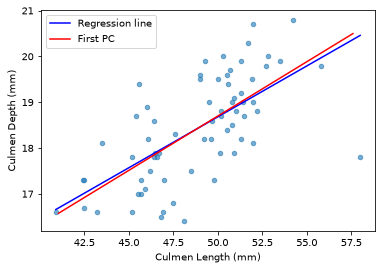

slopes: regression 0.222 | first PC 0.237


In [9]:
from sklearn.linear_model import LinearRegression

lr = LinearRegression().fit(penguins[["Culmen Length (mm)"]], penguins["Culmen Depth (mm)"])
x_range = pd.DataFrame({"Culmen Length (mm)": np.linspace(penguins.iloc[:, 0].min(), penguins.iloc[:, 0].max(), 100)})
t = np.linspace(-8, 9, 100)
pc_line = pca_1d.mean_ + t[:, None] * pca_1d.components_[0]

fig, ax = plt.subplots(figsize=(6, 4))
penguins.plot.scatter(x="Culmen Length (mm)", y="Culmen Depth (mm)", alpha=0.6, ax=ax)
ax.plot(x_range, lr.predict(x_range), "b-", label="Regression line")
ax.plot(pc_line[:, 0], pc_line[:, 1], "r-", label="First PC")
ax.legend()
plt.show()
print("slopes: regression", round(lr.coef_[0], 3), "| first PC", round(pca_1d.components_[0, 1] / pca_1d.components_[0, 0], 3))

> 📖 **Read more:** [extras/10-pca-intuitions.ipynb](extras/10-pca-intuitions.ipynb) (INRIA MOOC): the full notebook, including the picture of vertical versus perpendicular distances. [extras/11-pca-iris.ipynb](extras/11-pca-iris.ipynb) (scikit-learn gallery): the iris measurements in a pair plot and on the first three components in 3-D. [extras/14-pca-in-depth.ipynb](extras/14-pca-in-depth.ipynb) (Python Data Science Handbook): PCA in depth, including eigenfaces.

### PCA on the wine data: explained variance and loadings

Now a table with many columns: 178 wines from three cultivars with 13 chemical measurements (the `wine` data set that ships with scikit-learn). The cultivar is kept aside; PCA does not see it. We standardise, fit `PCA()` with all components and look at the explained variance. **Predict:** what share will PC1 explain *without* standardising, when one column (proline) has values in the hundreds and thousands?

In [10]:
from sklearn.datasets import load_wine

wine = load_wine(as_frame=True)
Zw = StandardScaler().fit_transform(wine.data)
pca = PCA().fit(Zw)
print("explained variance ratio, first five:", pca.explained_variance_ratio_[:5].round(3))
print("cumulative after 2 and 5 PCs:", pca.explained_variance_ratio_.cumsum()[[1, 4]].round(2))
print("PC1 share without standardising:", PCA().fit(wine.data).explained_variance_ratio_[0].round(3))

explained variance ratio, first five: [0.362 0.192 0.111 0.071 0.066]
cumulative after 2 and 5 PCs: [0.55 0.8 ]
PC1 share without standardising: 0.998


After standardising, two components keep about 55 % of the variance and five about 80 %. Without standardising, proline alone becomes PC1 and "explains" almost everything, simply because its numbers are large. PCA uses variance, so **standardise unless all columns share one unit**.

Next the loadings of PC1 and PC2 as a table. `pca.components_` has one row per component and one column per original feature; we transpose it and sort by the absolute PC1 loading.

In [11]:
loadings = pd.DataFrame(pca.components_[:2].T, index=wine.data.columns, columns=["PC1", "PC2"])
loadings.reindex(loadings["PC1"].abs().sort_values(ascending=False).index).round(2)

,PC1,PC2
flavanoids,0.42,-0.00
total_phenols,0.39,0.07
od280/od315_of_diluted_wines,0.38,-0.16
proanthocyanins,0.31,0.04
nonflavanoid_phenols,-0.30,0.03
hue,0.30,-0.28
proline,0.29,0.36
malic_acid,-0.25,0.22
alcalinity_of_ash,-0.24,-0.01
alcohol,0.14,0.48


PC1 is a "phenol" axis: flavanoids, total phenols and the OD280/OD315 ratio load highest. PC2 is led by colour intensity, alcohol and proline. The **sign** of a component is arbitrary: two libraries may return PC1 and −PC1.

![Left: scree plot for the wine data with bars falling from 36 % for PC1 to under 1 % for PC13 and a cumulative line passing 80 % at five components. Right: biplot of PC1 against PC2 with the three cultivars as separated point clouds and arrows for the six largest loadings](../figures/pca_scree_biplot.png)

The **biplot** on the right combines scores (points) and loadings (arrows). Points lie in the direction of the arrows of the columns on which they are high. The three cultivars, which PCA did not see, separate in the first two components.

> **Note.** High explained variance is not high relevance. PCA keeps the directions with most variance, not those most related to a target; a small component can be the one that predicts churn. And inside a model pipeline PCA is a fitted preparation step like scaling: fit it on training data only (Session 7).

`PCA(n_components=0.8)` keeps as many components as needed for 80 % of the variance; `pca.inverse_transform(scores)` maps scores back to the original columns.

Where PCA is used: population genetics (the first two PCs of European genotypes reproduce the map of Europe; Novembre et al., 2008), finance (three components, "level", "slope" and "curvature", describe most movements of government bond yields; Litterman and Scheinkman, 1991), faces ("eigenfaces"; Turk and Pentland, 1991), and survey indices built from many items.

### Scaling and preprocessing before PCA

*Adapted from [Preprocessing for PCA](https://github.com/INRIA/scikit-learn-mooc/blob/main/notebooks/dimred_preprocessing.ipynb) (INRIA scikit-learn MOOC, CC BY 4.0).*

If one feature spans a much larger range than another, its variance is measured on that larger scale and dominates the decomposition, whatever its importance. Scaling fixes that, but *which* scaler? Different distributions interact with scaling differently, and that changes the components. We use houses from Ames, Iowa (the Ames housing data), and drop the sale price as a reminder that PCA is unsupervised.

`components_` entries are the cosines of the angles between an original feature axis and a PC direction: near 0 means perpendicular, near ±1 means nearly parallel, and the sign has no meaning. **Squaring** them gives a "squared loading" that reads as a proportion: each row of `components_` is a unit vector, so its squared values sum to 1. The helper draws them as a heat map.

In [12]:
ames = pd.read_csv(DATA / "ames_housing_no_missing.csv").drop(columns="SalePrice")


def plot_sq_loadings(ax, pca, feature_names, col_order=None, decimals=2):
    comps = pca.components_ if col_order is None else pca.components_[:, col_order]
    names = feature_names if col_order is None else [feature_names[i] for i in col_order]
    sq = comps ** 2
    im = ax.imshow(sq, cmap="Blues", vmin=0, vmax=1, aspect="auto")
    for i, j in np.ndindex(sq.shape):
        ax.text(j, i, f"{sq[i, j]:.{decimals}f}", ha="center", va="center", fontsize=9)
    ax.set_xticks(range(len(names)), names, rotation=45, ha="right")
    ax.set_yticks(range(len(comps)), [f"PC{i + 1} ({v:.0%})" for i, v in enumerate(pca.explained_variance_ratio_)])
    return im

First three features on very different scales: `GrLivArea` (living area, about 300 to 5,000 square feet), `OverallQual` (quality score 1 to 10) and `YearBuilt` (about 1870 to 2010). Squared loadings of a 2-component PCA, raw and standardised:

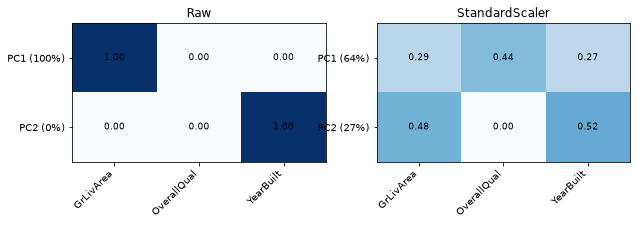

In [13]:
features_3d = ["GrLivArea", "OverallQual", "YearBuilt"]
fig, axes = plt.subplots(1, 2, figsize=(10, 2.5))
for ax, (title, pipe) in zip(axes, [("Raw", make_pipeline(PCA(2))), ("StandardScaler", make_pipeline(StandardScaler(), PCA(2)))]):
    pipe.fit(ames[features_3d])
    plot_sq_loadings(ax, pipe[-1], features_3d)
    ax.set_title(title)
plt.show()

Without scaling, PC1 is almost entirely `GrLivArea` and `OverallQual` barely appears, because its range (1–10) is tiny. After scaling, all three features contribute to PC1. Note that scaling removes the *magnitude* bias but does not make all directions equally important: correlated features still define a dominant direction.

#### Outliers and the choice of scaler

`StandardScaler` estimates the standard deviation from all rows, including outliers. `LotArea` is heavily skewed: most lots are around 10,000 square feet, a few far larger. `RobustScaler` divides by the interquartile range (IQR) instead, and skrub's `SquashingScaler` compresses values beyond a quantile range smoothly towards the centre. The next cell compares the IQR and the standard deviation of `LotArea`, then the squared loadings of four features under the three scalers.

std: 9981 sq ft | IQR: 4048 sq ft


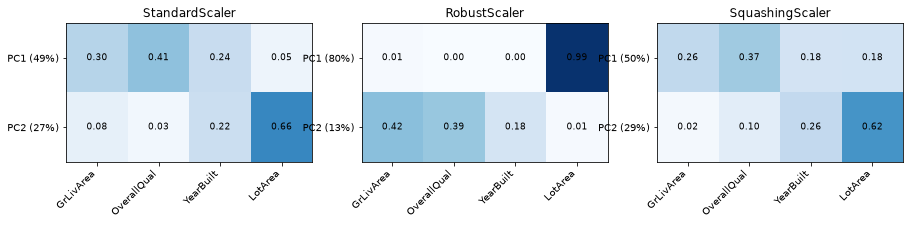

In [14]:
from sklearn.preprocessing import RobustScaler
from skrub import SquashingScaler

lot = ames["LotArea"]
print(f"std: {lot.std():.0f} sq ft | IQR: {lot.quantile(0.75) - lot.quantile(0.25):.0f} sq ft")
features_4d = features_3d + ["LotArea"]
scalers = [("StandardScaler", StandardScaler()), ("RobustScaler", RobustScaler()),
           ("SquashingScaler", SquashingScaler(quantile_range=(5.0, 95.0)))]
fig, axes = plt.subplots(1, 3, figsize=(15, 2.5))
for ax, (title, scaler) in zip(axes, scalers):
    pipe = make_pipeline(scaler, PCA(2)).fit(ames[features_4d])
    plot_sq_loadings(ax, pipe[-1], features_4d)
    ax.set_title(title)
plt.show()

The IQR of `LotArea` is much smaller than its standard deviation, so `RobustScaler` makes the outlier lots *more* extreme in scaled units, and PC1 becomes almost entirely `LotArea`: PCA spends its first direction separating a handful of huge lots. "Robust" refers to the scale estimate, not to the effect on outliers. With `StandardScaler`, PC1 is dominated by quality and living area and `LotArea` moves to PC2. `SquashingScaler` spreads the loadings most evenly. If you build an outlier detector, though, you may *want* the outliers to stay visible.

#### Sparse and one-hot columns

A **sparse** column is one that is zero for most rows. Such a column (pool area: nearly all houses have no pool, as the next cell shows) has little variance, so PCA pushes it into the last component and any reduction discards it, even if it matters for the price. One-hot columns behave the same way: frequent categories dominate the first components, rare ones end up in near-zero components, so PCA after one-hot encoding is not much different from dropping rare categories. The usual remedy is to keep binary and categorical features **outside** the PCA and concatenate them to its output with a `ColumnTransformer`.

In [15]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import Binarizer

print("share of houses without a pool:", round((ames["PoolArea"] == 0).mean(), 3))
ct = ColumnTransformer([("pca", make_pipeline(SquashingScaler(quantile_range=(5.0, 95.0)), PCA(2)), features_4d),
                        ("pool", Binarizer(), ["PoolArea"])]).set_output(transform="pandas")
ct.fit_transform(ames).head()

share of houses without a pool: 0.995


,pca__pca0,pca__pca1,pool__PoolArea
0,0.297390,-0.321014,0
1,-0.086678,-0.067111,0
2,0.397532,-0.147387,0
3,-0.071222,0.226889,0
4,0.760872,-0.017473,0


The result has two components for the continuous variation in size, quality and age, plus one exact 0/1 column for pool presence. PCA can also be a diagnostic tool: the squared-loading heat maps show which features co-vary, which are dominated by a few extreme rows, and which encodings produce components that reflect frequency rather than meaning.

> 📖 **Read more:** [extras/13-pca-as-preprocessing.ipynb](extras/13-pca-as-preprocessing.ipynb) (INRIA MOOC): the full notebook with 3-D views, the PC1 lines under each scaler and the one-hot heat map. [extras/01-feature-scaling.ipynb](extras/01-feature-scaling.ipynb) (scikit-learn gallery): the first principal component of the wine data with and without scaling.

### How many components?

*Adapted from [Choice of n_components in the unsupervised case](https://github.com/INRIA/scikit-learn-mooc/blob/main/notebooks/dimred_components.ipynb) (INRIA scikit-learn MOOC, CC BY 4.0).*

When a target exists, the number of components is a hyperparameter tuned by cross-validation like any other. Without one, indirect criteria are needed, and each encodes a different assumption about what "enough" means:

- **Variance thresholds**: keep enough components for 90 % or 95 % of the variance. `np.searchsorted(cumulative, 0.90) + 1` finds the first count that crosses the threshold, and `PCA(n_components=0.90)` does the same inside scikit-learn.
- **The Kaiser criterion**: keep components that each explain more than one original variable would on average, that is more than 1/p of the total variance for p standardised features.
- An "elbow" in the scree plot is the historical rule; it is harder to read and less stable.

In [16]:
cumulative = np.cumsum(pca.explained_variance_ratio_)
threshold_90 = np.searchsorted(cumulative, 0.90) + 1
threshold_95 = np.searchsorted(cumulative, 0.95) + 1
kaiser_n = int(np.sum(pca.explained_variance_ratio_ > 1 / Zw.shape[1]))
print("90 %:", threshold_90, "components | 95 %:", threshold_95, "| Kaiser:", kaiser_n)
print("PCA(0.90) keeps", make_pipeline(StandardScaler(), PCA(n_components=0.90)).fit(wine.data)[-1].n_components_)

90 %: 8 components | 95 %: 10 | Kaiser: 3
PCA(0.90) keeps 8


These numbers come from one sample. A PCA fitted on a slightly different sample gives slightly different variances, so "we keep 90 % of the variance" is only approximately true. Refitting on 20 random halves of the wine data shows how much the variance retained by a fixed number of components varies; report "N components keep X ± Y % of the variance across subsamples" instead of a single figure.

In [17]:
from sklearn.model_selection import train_test_split

split_cum = []
for seed in range(20):
    half, _ = train_test_split(wine.data, train_size=0.5, random_state=seed)
    split_cum.append(np.cumsum(make_pipeline(StandardScaler(), PCA()).fit(half)[-1].explained_variance_ratio_))
split_cum = np.array(split_cum)
for n_comp in [kaiser_n, threshold_90, threshold_95]:
    v = split_cum[:, n_comp - 1] * 100
    print(f"{n_comp} components -> {v.mean():.1f} +/- {v.std():.1f} % variance retained across splits")

3 components -> 67.3 +/- 1.2 % variance retained across splits
8 components -> 92.6 +/- 0.3 % variance retained across splits
10 components -> 96.6 +/- 0.2 % variance retained across splits


The INRIA notebook continues with a downstream check: k-means with silhouette curves after keeping the Kaiser number of components versus the 90 % number. With few components the silhouette peaks consistently at three clusters (the three cultivars); with more components the curves spread out, because the extra components add mostly noise and, in more dimensions, distances concentrate and silhouettes shrink. In a supervised pipeline, prefer cross-validation.

> 📖 **Read more:** [extras/12-pca-components.ipynb](extras/12-pca-components.ipynb) (INRIA MOOC): the stability plots and the clustering check.

### PCA on images: digits and noise filtering

*Code adapted from [In Depth: Principal Component Analysis](https://jakevdp.github.io/PythonDataScienceHandbook/05.09-principal-component-analysis.html), Python Data Science Handbook (Jake VanderPlas, code MIT). The text of that chapter is CC BY-NC-ND and is not reproduced; the explanations here are ours.*

The digits data have 64 columns, one per pixel. Two components are far too few to keep the information (the next cell prints how much they keep), but the cumulative curve shows how many we would need. All pixels share one unit (grey level 0–16), so no scaling is needed.

variance kept by 2 PCs: 0.285 | PCs needed for 90 %: 21


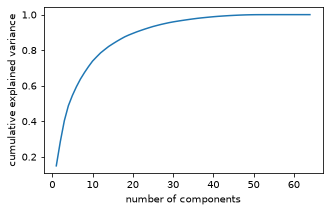

In [18]:
from sklearn.datasets import load_digits

digits = load_digits()
pca_digits = PCA().fit(digits.data)
cum = np.cumsum(pca_digits.explained_variance_ratio_)
print("variance kept by 2 PCs:", cum[1].round(3), "| PCs needed for 90 %:", np.searchsorted(cum, 0.9) + 1)
plt.figure(figsize=(5, 3))
plt.plot(np.arange(1, 65), cum)
plt.gca().set(xlabel="number of components", ylabel="cumulative explained variance")
plt.show()

#### Noise filtering

Components with large variance carry the signal; noise spreads thinly over all components. Reconstructing the data from the first few components therefore removes much of the noise. We add Gaussian noise to the digits, fit a PCA that keeps 50 % of the variance of the *noisy* data, and reconstruct with `inverse_transform`.

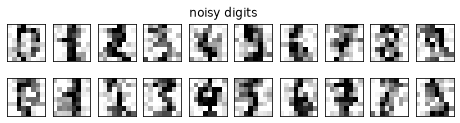

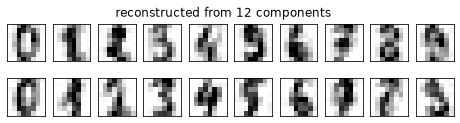

In [19]:
def plot_digits(data, title):
    fig, axes = plt.subplots(2, 10, figsize=(8, 1.8), subplot_kw={"xticks": [], "yticks": []})
    for i, ax in enumerate(axes.flat):
        ax.imshow(data[i].reshape(8, 8), cmap="binary", interpolation="nearest", clim=(0, 16))
    fig.suptitle(title)
    plt.show()


noisy = np.random.default_rng(42).normal(digits.data, 4)
pca_noise = PCA(0.50).fit(noisy)
plot_digits(noisy, "noisy digits")
plot_digits(pca_noise.inverse_transform(pca_noise.transform(noisy)), f"reconstructed from {pca_noise.n_components_} components")

The reconstructions are smoother and easier to read than the noisy inputs. The same idea underlies "eigenfaces": a face image is approximated by a weighted sum of a few hundred component images; the PDSH chapter shows it on a face data set that must be downloaded.

## t-SNE and UMAP for visualisation

PCA is linear: it can only rotate and project. Data that lie on a curved surface (images of the same digit written in different ways, for example) are not separated by any flat projection. Two non-linear methods, t-SNE and UMAP, focus on **neighbourhoods** instead of variance. Both keep **local** structure: rows that are neighbours in the original space stay neighbours in the 2-D map.

Analogy: a map of the London Underground. Neighbouring stations are next to each other, and you can see which lines connect, but distances and directions between distant parts of the map mean little.

### t-SNE and the perplexity

*Adapted from [t-SNE: The effect of various perplexity values on the shape](https://scikit-learn.org/stable/auto_examples/manifold/plot_t_sne_perplexity.html) (scikit-learn developers, BSD-3-Clause).*

**t-SNE** (t-distributed stochastic neighbour embedding; van der Maaten and Hinton, 2008) turns distances into probabilities that two rows are neighbours, in the original space and in a 2-D map, and moves the points in the map until the two sets of probabilities match. The **perplexity** (typically 5–50) sets roughly how many neighbours each point considers.

The example runs t-SNE on two concentric circles and on an S-shaped surface for several perplexities. The shapes tend to become clearer as the perplexity grows, but the size, the distance and the shape of the clusters vary with the initialisation and the perplexity and do not always convey a meaning. For higher perplexities t-SNE finds the topology of the two circles, though the size and distance of the circles differ from the original; for the S-curve the shapes diverge from the true topology even for larger perplexities.

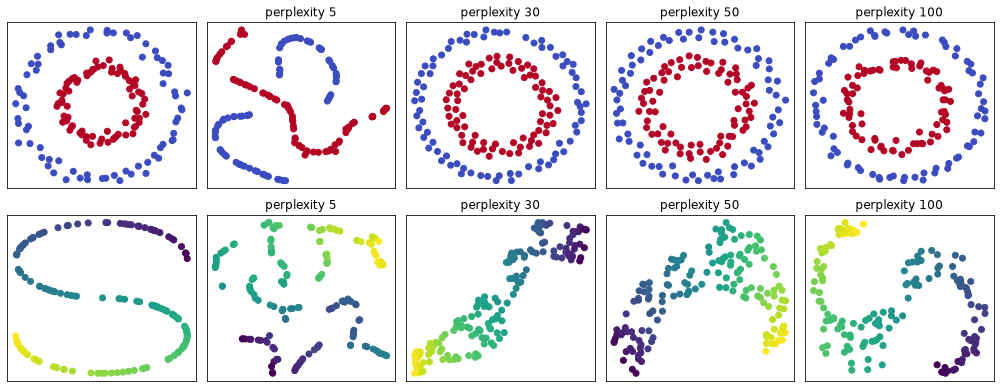

In [20]:
from sklearn import datasets as skdata

Xc, yc = skdata.make_circles(n_samples=150, factor=0.5, noise=0.05, random_state=0)
Xs, cs = skdata.make_s_curve(150, random_state=0)
perplexities = [5, 30, 50, 100]
fig, axes = plt.subplots(2, 5, figsize=(14, 5.5))
axes[0, 0].scatter(*Xc.T, c=yc, cmap="coolwarm")
axes[1, 0].scatter(Xs[:, 0], Xs[:, 2], c=cs)
for i, perp in enumerate(perplexities, start=1):
    for row, (data, colour) in enumerate([(Xc, yc), (Xs, cs)]):
        emb = TSNE(perplexity=perp, init="random", max_iter=300, random_state=0).fit_transform(data)
        axes[row, i].scatter(*emb.T, c=colour, cmap="coolwarm" if row == 0 else "viridis")
        axes[row, i].set_title(f"perplexity {perp}")
for ax in axes.flat:
    ax.set(xticks=[], yticks=[])
plt.tight_layout()

> 📖 **Read more:** [extras/15-tsne-perplexity.ipynb](extras/15-tsne-perplexity.ipynb) (scikit-learn gallery): the full example, including a uniform grid; and the interactive article by Wattenberg, Viégas and Johnson (2016), *How to use t-SNE effectively*, https://distill.pub/2016/misread-tsne/.

### UMAP and its parameters

*Adapted from [Basic UMAP Usage and Parameters](https://github.com/lmcinnes/umap/blob/master/notebooks/UMAP%20usage%20and%20parameters.ipynb) (Leland McInnes and contributors, umap-learn documentation, BSD-3-Clause), itself based on work by Philippe Rivière for visionscarto.net.*

**UMAP** (uniform manifold approximation and projection; McInnes, Healy and Melville, 2018) builds a graph of the **n_neighbors** nearest neighbours of every row and lays the graph out in 2-D. **min_dist** sets how tightly points may be packed. UMAP is usually faster than t-SNE, keeps somewhat more global structure, and can transform new rows.

UMAP seeks to learn the manifold structure of the data and find a low-dimensional embedding that preserves its essential topological structure. To make 4-dimensional data "visible", the example draws 800 points uniformly from a 4-D cube and interprets each as an (R, G, B, alpha) colour. Points that are near each other in 4-D are similar colours, so a good 2-D map places similar colours together.

In [21]:
import warnings

warnings.filterwarnings("ignore", message="IProgress not found")
import umap  # noqa: E402

colours = np.random.RandomState(42).rand(800, 4)


def draw_umap(ax, **params):
    emb = umap.UMAP(random_state=42, n_jobs=1, **params).fit_transform(colours)
    ax.scatter(emb[:, 0], emb[:, 1] if emb.shape[1] > 1 else np.arange(len(emb)), c=colours, s=6)
    ax.set(title=", ".join(f"{k} = {v}" for k, v in params.items()), xticks=[], yticks=[])

#### `n_neighbors`

`n_neighbors` controls the balance between local and global structure: it limits the size of the neighbourhood UMAP looks at. Low values concentrate on very local structure (with `n_neighbors=2` UMAP glues together small chains and leaves many disconnected pieces); large values look at larger neighbourhoods and capture the broad structure at the cost of fine detail. The default is 15.

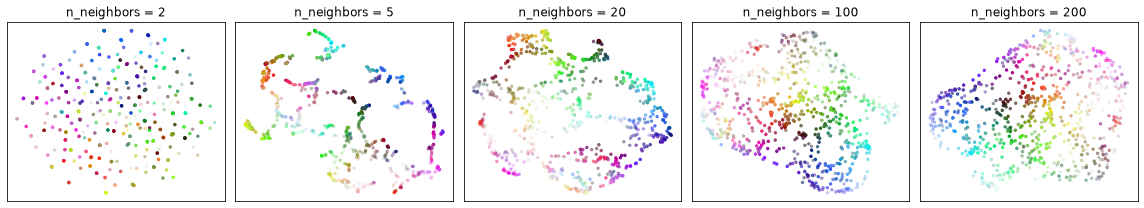

In [22]:
fig, axes = plt.subplots(1, 5, figsize=(16, 3))
for ax, n in zip(axes, [2, 5, 20, 100, 200]):
    draw_umap(ax, n_neighbors=n)
plt.tight_layout()

#### `min_dist`

`min_dist` controls how tightly UMAP may pack points together: literally the minimum distance between points in the map. Low values give clumpier embeddings, useful for clustering or fine structure; larger values push points apart and favour the broad topological structure. The default is 0.1.

#### `n_components` and `metric`

`n_components` sets the dimension of the map. Unlike t-SNE, UMAP scales well with the embedding dimension, so it can also produce 10 or 50 dimensions as input for density-based clustering. `metric` sets how distances are computed in the input space: Euclidean by default, but also `"manhattan"`, `"cosine"`, `"correlation"`, metrics for binary data such as `"jaccard"` and `"hamming"`, and custom metrics compiled with numba.

The next cell shows four values of `min_dist` and, in the last panel, a one-dimensional map (`n_components=1`, drawn against the row number).

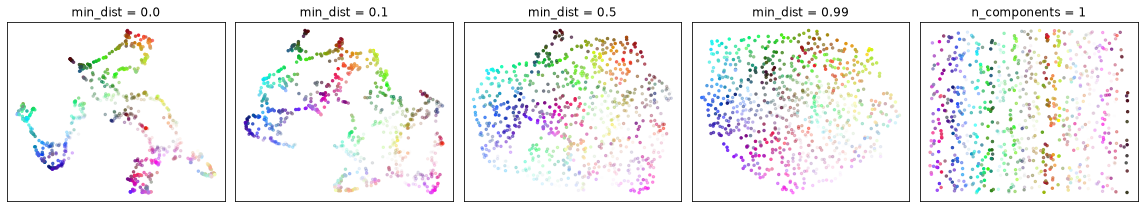

In [23]:
fig, axes = plt.subplots(1, 5, figsize=(16, 3))
for ax, dist in zip(axes, [0.0, 0.1, 0.5, 0.99]):
    draw_umap(ax, min_dist=dist)
draw_umap(axes[4], n_components=1)
plt.tight_layout()

> 📖 **Read more:** [extras/18-umap-parameters.ipynb](extras/18-umap-parameters.ipynb) (umap-learn documentation): the original notebook, including 3-D embeddings and custom metrics on hue, saturation and lightness; and Coenen and Pearce (2019), *Understanding UMAP*, https://pair-code.github.io/understanding-umap/.

### Trustworthiness: PCA, t-SNE and UMAP on the digits

**Trustworthiness** (0 to 1) measures this: how far the nearest neighbours of each point in the map are also among its true nearest neighbours.

Next we map the 1,797 digits with PCA, t-SNE and UMAP and compute the trustworthiness of each map. The labels are used only to colour the points.

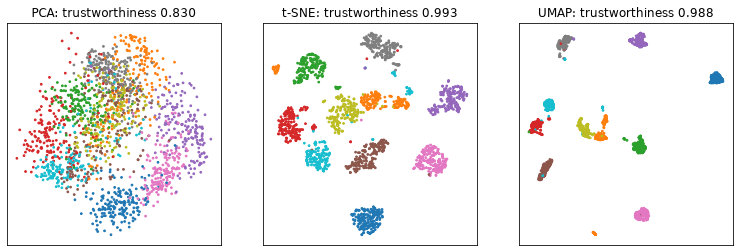

In [24]:
X_digits = digits.data
maps = {"PCA": PCA(n_components=2).fit_transform(X_digits),
        "t-SNE": TSNE(n_components=2, perplexity=30, random_state=0).fit_transform(X_digits),
        "UMAP": umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=0, n_jobs=1).fit_transform(X_digits)}
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, (name, emb) in zip(axes, maps.items()):
    ax.scatter(*emb.T, c=digits.target, s=3, cmap="tab10")
    ax.set(title=f"{name}: trustworthiness {trustworthiness(X_digits, emb, n_neighbors=10):.3f}", xticks=[], yticks=[])
plt.show()

In the t-SNE and UMAP maps the ten digits form ten largely separate groups, although the labels were not used; in the PCA map they overlap, because two components keep only a small part of the variance.

Where such maps are used: single-cell biology (maps of thousands of cells coloured by cell type; Becht et al., 2019), inspecting embeddings of words or images, and finding mislabelled examples (a point of one colour inside a group of another).

### Manifold learning: MDS, LLE, Isomap and others

*Code adapted from [In Depth: Manifold Learning](https://jakevdp.github.io/PythonDataScienceHandbook/05.10-manifold-learning.html), Python Data Science Handbook (Jake VanderPlas, code MIT; explanations ours), and [Comparison of Manifold Learning methods](https://scikit-learn.org/stable/auto_examples/manifold/plot_compare_methods.html) (scikit-learn developers, BSD-3-Clause).*

t-SNE and UMAP belong to a family called **manifold learning**: methods that assume the data lie on a low-dimensional surface (a "manifold") bent through a higher-dimensional space, like a sheet of paper crumpled in a room. To see what that means, we draw 1,000 points from the shape of the word "HELLO". The helper renders the word into a temporary image (in a `tempfile` folder, so nothing is written to the repository) and keeps random points that fall on the letters.

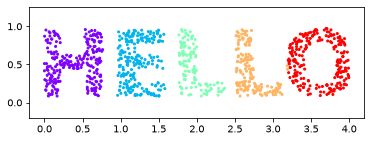

In [25]:
import tempfile

from matplotlib.image import imread


def make_hello(N=1000, rseed=42):
    fig, ax = plt.subplots(figsize=(4, 1))
    fig.subplots_adjust(left=0, right=1, bottom=0, top=1)
    ax.axis("off")
    ax.text(0.5, 0.4, "HELLO", va="center", ha="center", weight="bold", size=85)
    with tempfile.TemporaryDirectory() as tmp:
        fig.savefig(Path(tmp) / "hello.png")
        plt.close(fig)
        data = imread(Path(tmp) / "hello.png")[::-1, :, 0].T
    X = np.random.RandomState(rseed).rand(4 * N, 2)
    i, j = (X * data.shape).astype(int).T
    X = X[data[i, j] < 1]
    X[:, 0] *= data.shape[0] / data.shape[1]
    return X[:N][np.argsort(X[:N, 0])]


Xh = make_hello(1000)
colorize = dict(c=Xh[:, 0], cmap=plt.get_cmap("rainbow", 5))
plt.figure(figsize=(6, 2))
plt.scatter(*Xh.T, s=4, **colorize)
plt.axis("equal")
plt.show()

#### Multidimensional scaling (MDS)

**Multidimensional scaling (MDS)** needs only the table of pairwise distances between rows. It places points in a low-dimensional map so that map distances match the given distances as well as possible. Rotating or shifting the data does not change the distances, so MDS recovers the word up to a rotation or reflection. `metric="precomputed"` tells MDS that we pass a distance matrix.

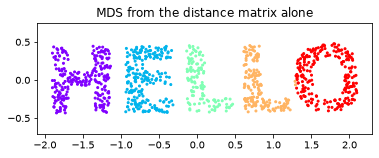

In [26]:
from sklearn.manifold import MDS
from sklearn.metrics import pairwise_distances

D = pairwise_distances(Xh)
out = MDS(n_components=2, metric="precomputed", init="classical_mds", n_init=1, random_state=1701).fit_transform(D)
plt.figure(figsize=(6, 2))
plt.scatter(*out.T, s=4, **colorize)
plt.axis("equal")
plt.title("MDS from the distance matrix alone")
plt.show()

#### Locally linear embedding (LLE)

**Locally linear embedding** (LLE) looks only at each point's nearest neighbours, describes each point as a weighted combination of them, and finds a 2-D layout that keeps those local weights. To see why that matters, we bend the word into an S-shaped surface in three dimensions. The points still lie on a 2-D sheet, but straight-line distances through the room no longer follow the sheet: the two ends of the "S" are close in space although far apart along the surface. MDS, which keeps straight-line distances, fails to unroll it; LLE unrolls the sheet.

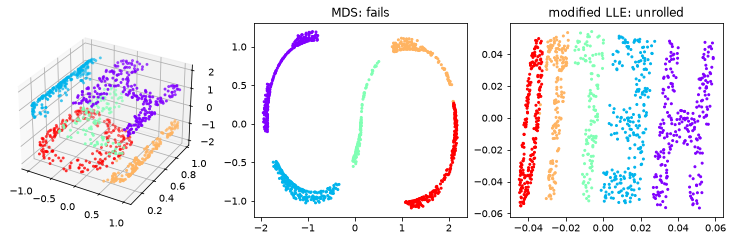

In [27]:
from sklearn.manifold import LocallyLinearEmbedding

t = (Xh[:, 0] - 2) * 0.75 * np.pi
XS = np.vstack((np.sin(t), Xh[:, 1], np.sign(t) * (np.cos(t) - 1))).T          # "HELLO" bent into an S
fig = plt.figure(figsize=(13, 3.5))
ax = fig.add_subplot(1, 3, 1, projection="3d")
ax.scatter3D(*XS.T, s=4, **colorize)
outS = MDS(n_components=2, init="classical_mds", n_init=1, random_state=2).fit_transform(XS)
fig.add_subplot(1, 3, 2).scatter(*outS.T, s=4, **colorize)
lle = LocallyLinearEmbedding(n_neighbors=100, n_components=2, method="modified", eigen_solver="dense")
out_lle = lle.fit_transform(XS)
fig.add_subplot(1, 3, 3).scatter(*out_lle.T, s=4, **colorize)
fig.axes[1].set_title("MDS: fails")
fig.axes[2].set_title("modified LLE: unrolled")
plt.show()

#### Isomap, spectral embedding and the others compared

The scikit-learn comparison runs the main manifold methods on a standard S-curve of 1,500 points:

- **LLE** variants can be thought of as a series of local PCAs, globally compared to find the best non-linear embedding;
- **Isomap** keeps *geodesic* distances: distances measured along the neighbourhood graph, that is along the surface;
- **MDS** keeps the original distances as well as possible;
- **spectral embedding** (Laplacian eigenmaps) uses a spectral decomposition of the neighbourhood graph;
- **t-SNE** converts similarities to probabilities and matches them; its cost function is not convex, so different starts give different results.

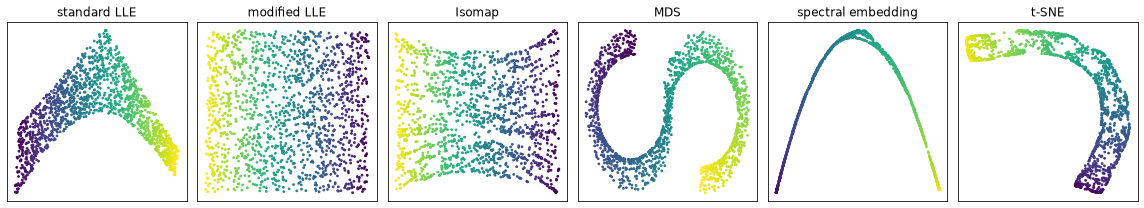

In [28]:
from sklearn import manifold

S_points, S_color = skdata.make_s_curve(1500, random_state=0)
methods = {
    "standard LLE": manifold.LocallyLinearEmbedding(n_neighbors=12, method="standard", random_state=0),
    "modified LLE": manifold.LocallyLinearEmbedding(n_neighbors=12, method="modified", random_state=0),
    "Isomap": manifold.Isomap(n_neighbors=12, p=1),
    "MDS": manifold.MDS(max_iter=50, n_init=1, init="classical_mds", random_state=0),
    "spectral embedding": manifold.SpectralEmbedding(n_neighbors=12, random_state=42),
    "t-SNE": manifold.TSNE(perplexity=30, init="random", max_iter=250, random_state=0),
}
fig, axes = plt.subplots(1, 6, figsize=(16, 3))
for ax, (name, model) in zip(axes, methods.items()):
    ax.scatter(*model.fit_transform(S_points).T, c=S_color, s=3)
    ax.set(title=name, xticks=[], yticks=[])
plt.tight_layout()

Modified LLE and Isomap unroll the S into a flat rectangle with the colours in order; standard LLE and spectral embedding keep the colour order but squash the sheet into a curve; MDS keeps the bent S; t-SNE keeps the order as a curved band. In practice, these classic methods scale poorly and are sensitive to noise; for real high-dimensional data t-SNE and UMAP are the usual choice, and PCA remains the first thing to try.

> 📖 **Read more:** [extras/16-manifold-learning.ipynb](extras/16-manifold-learning.ipynb) (Python Data Science Handbook): Isomap on faces and on MNIST digits (data downloaded on first run). [extras/17-manifold-methods-compared.ipynb](extras/17-manifold-methods-compared.ipynb) (scikit-learn gallery): all variants with 3-D views.

### What such maps cannot show

A t-SNE or UMAP map keeps neighbourhoods and nothing else. Distances *between* groups, the *size* of groups and the empty space between them have no reliable meaning: t-SNE expands dense groups and shrinks sparse ones. Different seeds and settings can give different pictures. So:

- do not cluster on a t-SNE map and do not read distances between groups; cluster on the original data or on PCA scores and use the map only to look;
- fix the seed and try several settings; a structure that appears for one perplexity only is not a finding (Wattenberg, Viégas and Johnson, 2016);
- for data with hundreds of columns (text embeddings in Session 14), reduce to 30–50 principal components first, then run t-SNE or UMAP on the scores.

## Worked example · What do Berlin listings offer? PCA of the amenities

Every Airbnb listing has a list of **amenities** chosen by the host from a form: "Wifi", "Kitchen", "Hair dryer", "Wine glasses" and so on. As a table this is one 0/1 column per amenity (**indicator** columns), thousands of them, most rare. Such tables are wide and redundant: a listing with "Cooking basics" usually also has "Dishes and silverware". PCA shows which bundles vary together and summarises a listing's equipment in a few scores.

All indicator columns share one unit (0 or 1), so we run PCA **without** standardising (standardising would give rare amenities the same weight as common ones). Columns that almost every listing has or almost none has carry little information and are dropped first.

The next cell parses the amenity lists (`json.loads` turns the text '["Wifi", "Kitchen"]' into a Python list) and turns them into indicator columns with `MultiLabelBinarizer`.

In [29]:
import json

from sklearn.preprocessing import MultiLabelBinarizer

listings = pd.read_parquet("case-study/data/airbnb/listings.parquet")
mlb = MultiLabelBinarizer()
A = pd.DataFrame(mlb.fit_transform(listings["amenities"].apply(json.loads)), columns=mlb.classes_, index=listings.index)
share = A.mean()
A = A.loc[:, (share >= 0.05) & (share <= 0.95)]               # drop very rare and near-universal items
print(len(mlb.classes_), "different amenity labels; kept", A.shape[1], "columns for", A.shape[0], "listings")

2305 different amenity labels; kept 90 columns for 10221 listings


Next the PCA, its explained variance and the top loadings of the first two components. `nlargest` and `nsmallest` show the strongest positive and negative loadings.

In [30]:
pca_a = PCA().fit(A)
print("explained variance PC1-PC3:", pca_a.explained_variance_ratio_[:3].round(3))
print("cumulative after 2 and 10 PCs:", pca_a.explained_variance_ratio_.cumsum()[[1, 9]].round(2))
load_a = pd.DataFrame(pca_a.components_[:2].T, index=A.columns, columns=["PC1", "PC2"])
print("PC1 top:", load_a["PC1"].nlargest(4).round(2).to_dict())
print("PC2 top:", load_a["PC2"].nlargest(3).round(2).to_dict())
print("PC2 bottom:", load_a["PC2"].nsmallest(2).round(2).to_dict())

explained variance PC1-PC3: [0.215 0.056 0.047]
cumulative after 2 and 10 PCs: [0.27 0.48]
PC1 top: {'Hot water kettle': 0.22, 'Cooking basics': 0.21, 'Dining table': 0.21, 'Wine glasses': 0.21}
PC2 top: {'Heating': 0.39, 'Stove': 0.33, 'Coffee maker': 0.28}
PC2 bottom: {'Central heating': -0.27, 'Cleaning products': -0.17}


**Predict.** PC1 has positive loadings on almost all household items. What simple number per listing might it track? The next cell correlates the PC1 scores with the number of amenities listed, cross-tabulates the two heating labels behind PC2, and compares PC1 by room type.

In [31]:
scores_a = pca_a.transform(A)
print("correlation PC1 vs number of amenities:", round(np.corrcoef(scores_a[:, 0], A.sum(axis=1))[0, 1], 2))
print(pd.crosstab(A["Heating"], A["Central heating"]))
pd.Series(scores_a[:, 0], index=listings.index).groupby(listings["room_type"]).median().round(2)

correlation PC1 vs number of amenities: 0.98
Central heating     0     1
Heating                    
0                1281  2397
1                6543     0


room_type
Entire home/apt    0.57
Hotel room        -0.60
Private room      -0.93
Shared room       -1.03
dtype: float64

![Left: scree plot of the amenity columns with a first bar of 21 % and all further bars below 6 %. Middle: the ten largest PC1 loadings, all kitchen and household items of about 0.2. Right: PC1 against PC2 scores of the listings coloured by room type; entire homes lie mostly to the right, private rooms mostly to the left, and PC2 spreads the listings vertically without separating the room types](../figures/amenities_pca.png)

Three readings:

- **PC1 is the length of the amenity list.** Almost all columns load positively, led by kitchen and household items, and the scores correlate almost perfectly with the number of amenities listed. Entire homes score high, private and hotel rooms low.
- **PC2 is not about equipment at all.** It contrasts "Heating" with "Central heating", and the crosstab shows that no listing has both labels. Listings with "Central heating" also tend to use other specific labels. PC2 most likely separates two versions of the amenity form, a property of how the data were *entered*, not of the flats; the data cannot confirm this.
- **Two components keep only about a quarter of the variance**: amenities are a list of many fairly independent items, not a few strong bundles.

> **Note.** A component can encode the data-collection process. Changes of a form, a scraper or a coding scheme create correlated columns that PCA finds as a strong direction. Before naming a component, look at its loadings and ask whether they describe the objects or the way they were recorded. For very wide sparse tables (text, thousands of labels) use `TruncatedSVD`, which works on sparse matrices without centring; Session 13 uses it for TF-IDF vectors.

### A t-SNE map of the listings

Following the advice of the t-SNE section (reduce to principal components first), we run t-SNE on the first 20 amenity components (not on the raw 0/1 columns) for a random sample of 3,000 listings, and colour the map by room type, which t-SNE did not see.

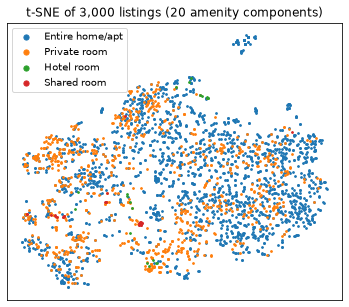

In [32]:
pick = np.random.default_rng(1).choice(len(A), size=3000, replace=False)
emb = TSNE(perplexity=30, init="pca", random_state=0).fit_transform(scores_a[pick, :20])
rooms = listings["room_type"].to_numpy()[pick]
fig, ax = plt.subplots(figsize=(6, 5))
for room in ["Entire home/apt", "Private room", "Hotel room", "Shared room"]:
    ax.scatter(*emb[rooms == room].T, s=3, label=room)
ax.set(title="t-SNE of 3,000 listings (20 amenity components)", xticks=[], yticks=[])
ax.legend(markerscale=3)
plt.show()

Private rooms concentrate in some regions and entire homes in others, with much overlap, and a few small islands appear at the edges. Before naming an island, check which amenities its listings share (for example the two heating labels behind PC2), and remember that its size and its distance from other islands carry no meaning.

## Model-based anomaly detection: Isolation Forest and local outlier factor

Session 4 flagged outliers one column at a time (IQR fences, z-scores, the median absolute deviation) and in combinations of columns with the Mahalanobis distance, which assumes one elliptical cloud. **Model-based** detectors need no such assumption. Each returns a **score** for every row; a threshold, or a guess of the share of anomalies (the **contamination**), turns scores into flags.

### Isolation Forest

*Adapted from [IsolationForest example](https://scikit-learn.org/stable/auto_examples/ensemble/plot_isolation_forest.html) (scikit-learn developers, BSD-3-Clause).*

**Isolation Forest** (Liu, Ting and Zhou, 2008) builds many random trees. Each tree splits the data on a random column at a random value, again and again, until every row stands alone. An unusual row is **isolated** after few splits. The score is the average path length to isolation: short path, anomalous. It needs no distances and scales to large data. Analogy: a game of "twenty questions" with random questions; an odd object is guessed after very few.

The scikit-learn example shows the isolation idea on toy data. It generates two Gaussian clusters, one round and one slightly deformed, plus uniformly scattered outliers.

Note the scikit-learn conventions: `predict` returns 1 for inliers and −1 for outliers, and `score_samples` and `negative_outlier_factor_` are *negative* scores (lower is more abnormal), so the course code flips their sign.

In [33]:
rng_if = np.random.RandomState(0)
n_samples, n_outliers = 120, 40
cluster_1 = 0.4 * rng_if.randn(n_samples, 2) @ np.array([[0.5, -0.1], [0.7, 0.4]]) + np.array([2, 2])
cluster_2 = 0.3 * rng_if.randn(n_samples, 2) + np.array([-2, -2])
outliers = rng_if.uniform(low=-4, high=4, size=(n_outliers, 2))
X_if = np.concatenate([cluster_1, cluster_2, outliers])
y_if = np.concatenate([np.ones(2 * n_samples, dtype=int), -np.ones(n_outliers, dtype=int)])
X_train, X_test, y_train, y_test = train_test_split(X_if, y_if, stratify=y_if, random_state=42)
clf_if = IsolationForest(max_samples=100, random_state=0).fit(X_train)

`DecisionBoundaryDisplay` colours the plane. With `response_method="predict"` it shows the binary decision; with `"decision_function"` it shows the measure of normality, derived from the path length averaged over the forest: values below 0 are flagged as anomalies, and the more negative the shorter the paths. The points show the true labels.

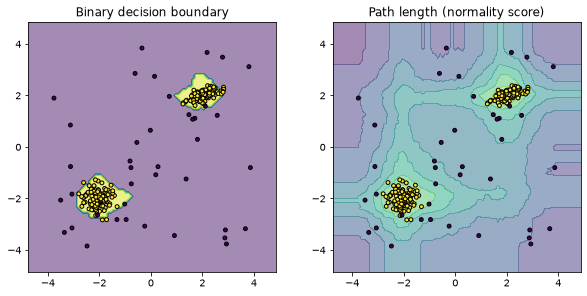

In [34]:
from sklearn.inspection import DecisionBoundaryDisplay

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
for ax, method, title in [(axes[0], "predict", "Binary decision boundary"),
                          (axes[1], "decision_function", "Path length (normality score)")]:
    disp = DecisionBoundaryDisplay.from_estimator(clf_if, X_if, response_method=method, alpha=0.5, ax=ax)
    ax.scatter(X_if[:, 0], X_if[:, 1], c=y_if, s=15, edgecolor="k")
    ax.set(title=title, aspect="equal")
plt.show()

### Local outlier factor (LOF)

*Adapted from [Outlier detection with Local Outlier Factor (LOF)](https://scikit-learn.org/stable/auto_examples/neighbors/plot_lof_outlier_detection.html) (scikit-learn developers, BSD-3-Clause).*

**Local outlier factor** (LOF; Breunig et al., 2000) compares the density around a row (how close its k nearest neighbours are) with the density around those neighbours. LOF near 1: as dense as its neighbourhood. LOF much larger than 1: in a much sparser region than its neighbours. Because it is *local*, it finds rows that are unusual relative to their own group, even when another group is sparse everywhere.

For LOF, the scikit-learn example draws circles whose radius grows with the outlier score. The number of neighbours `n_neighbors` should be larger than the smallest cluster that should count as normal (so that its members are not all outliers relative to each other) and smaller than the number of nearby points that could themselves be local outliers. Such information is rarely available; `n_neighbors=20` appears to work well in general. Used for outlier detection, LOF has no `predict`: it scores only the rows it was fitted on (`fit_predict`). For **novelty detection** (scoring new rows against clean training data) use `LocalOutlierFactor(novelty=True)`.

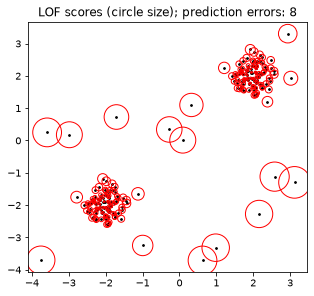

In [35]:
np.random.seed(42)
X_in = 0.3 * np.random.randn(100, 2)
X_lof = np.r_[X_in + 2, X_in - 2, np.random.uniform(low=-4, high=4, size=(20, 2))]
truth = np.r_[np.ones(200, dtype=int), -np.ones(20, dtype=int)]
lof_demo = LocalOutlierFactor(n_neighbors=20, contamination=0.1)
pred = lof_demo.fit_predict(X_lof)
s = lof_demo.negative_outlier_factor_
radius = (s.max() - s) / (s.max() - s.min())
plt.figure(figsize=(5, 4.5))
plt.scatter(*X_lof.T, color="k", s=3)
plt.scatter(*X_lof.T, s=1000 * radius, edgecolors="r", facecolors="none")
plt.title(f"LOF scores (circle size); prediction errors: {(pred != truth).sum()}")
plt.show()

### Choosing a detector

The flowchart sums up which detector fits which data, including the two methods of Session 4.

```mermaid
flowchart TD
    A["Suspicious rows?"] --> B{"One column<br/>at a time?"}
    B -->|yes| U["IQR fences, robust z-score<br/>(Session 4)"]
    B -->|no| C{"Roughly elliptical<br/>cloud?"}
    C -->|yes| M["Robust Mahalanobis distance<br/>(Session 4)"]
    C -->|no| D{"Groups of different<br/>density?"}
    D -->|yes| L["Local outlier factor"]
    D -->|no| I["Isolation Forest"]
    U --> R["Rank, inspect, decide:<br/>error, rare case or new pattern"]
    M --> R
    L --> R
    I --> R
```

A small example continues Session 4: a person is 192 cm tall and weighs 55 kg. Neither value is extreme alone, but the combination is. **Predict:** which of the four methods will flag this person? The cell simulates 500 people with weight correlated with height, then adds the tall, light person as row 500.

In [36]:
from scipy.stats import chi2
from sklearn.covariance import MinCovDet

rng = np.random.default_rng(0)
height = rng.normal(172, 9, 500)
weight = 0.9 * height - 85 + rng.normal(0, 6, 500)
Xp = np.vstack([np.column_stack([height, weight]), [192, 55]])

print("z-scores of row 500:", ((Xp[500] - Xp.mean(axis=0)) / Xp.std(axis=0)).round(1))
d2 = MinCovDet(random_state=0).fit(Xp).mahalanobis(Xp)
print("robust Mahalanobis distance:", np.sqrt(d2[500]).round(1), "| rows beyond the 99.9 % cut-off:", (d2 > chi2.ppf(0.999, df=2)).sum())
iso_p = IsolationForest(contamination=0.01, random_state=0).fit(Xp)
iso_score = -iso_p.score_samples(Xp)                          # higher = more anomalous
print("Isolation Forest flag (1 = inlier):", iso_p.predict(Xp)[500], "| rows scoring higher:", (iso_score > iso_score[500]).sum())
lof_p = LocalOutlierFactor(n_neighbors=20, contamination=0.01)
print("LOF flag:", lof_p.fit_predict(Xp)[500], "| LOF:", round(-lof_p.negative_outlier_factor_[500], 2))

z-scores of row 500: [ 2.2 -1.4]
robust Mahalanobis distance: 6.5 | rows beyond the 99.9 % cut-off: 3


Isolation Forest flag (1 = inlier): 1 | rows scoring higher: 5
LOF flag: -1 | LOF: 4.22


The z-scores miss the person; the robust Mahalanobis distance and LOF find them. Isolation Forest does not flag them, because it splits along one column at a time, so a point that is unusual only in the *combination* of two correlated columns is not isolated quickly.

### Four detectors on toy data

*Adapted from [Comparing anomaly detection algorithms for outlier detection on toy datasets](https://scikit-learn.org/stable/auto_examples/miscellaneous/plot_anomaly_comparison.html) (scikit-learn developers, BSD-3-Clause).*

Each data set has one or two modes (regions of high density) and 15 % uniform noise; 0.15 is also the contamination given to each detector. Observations from the example:

- the **robust covariance** estimator (`EllipticEnvelope`, the model behind the robust Mahalanobis distance) assumes Gaussian data and learns an ellipse, so it degrades when the data are not unimodal, though it is robust to outliers;
- the **one-class SVM** is sensitive to outliers and best suited to novelty detection on clean training data;
- **Isolation Forest** and **LOF** perform reasonably on multi-modal data; LOF has an advantage when the modes have different densities, because it compares each sample only with its neighbours;
- on uniformly distributed data it is hard to call any point abnormal; a good detector should then give all samples similar scores.

Black lines show decision boundaries (LOF has none, because it cannot score new points in outlier-detection mode); orange points are flagged.

In [37]:
from sklearn import svm
from sklearn.covariance import EllipticEnvelope
from sklearn.datasets import make_blobs, make_moons

frac, n_tot = 0.15, 300
n_out = int(frac * n_tot)
blobs = dict(random_state=0, n_samples=n_tot - n_out, n_features=2)
toy = [make_blobs(centers=[[0, 0], [0, 0]], cluster_std=0.5, **blobs)[0],
       make_blobs(centers=[[2, 2], [-2, -2]], cluster_std=[0.5, 0.5], **blobs)[0],
       make_blobs(centers=[[2, 2], [-2, -2]], cluster_std=[1.5, 0.3], **blobs)[0],
       4.0 * (make_moons(n_samples=n_tot, noise=0.05, random_state=0)[0] - np.array([0.5, 0.25])),
       14.0 * (np.random.RandomState(42).rand(n_tot, 2) - 0.5)]
detectors = {"Robust covariance": EllipticEnvelope(contamination=frac, random_state=42),
             "One-class SVM": svm.OneClassSVM(nu=frac, kernel="rbf", gamma=0.1),
             "Isolation Forest": IsolationForest(contamination=frac, random_state=42),
             "LOF": LocalOutlierFactor(n_neighbors=35, contamination=frac)}

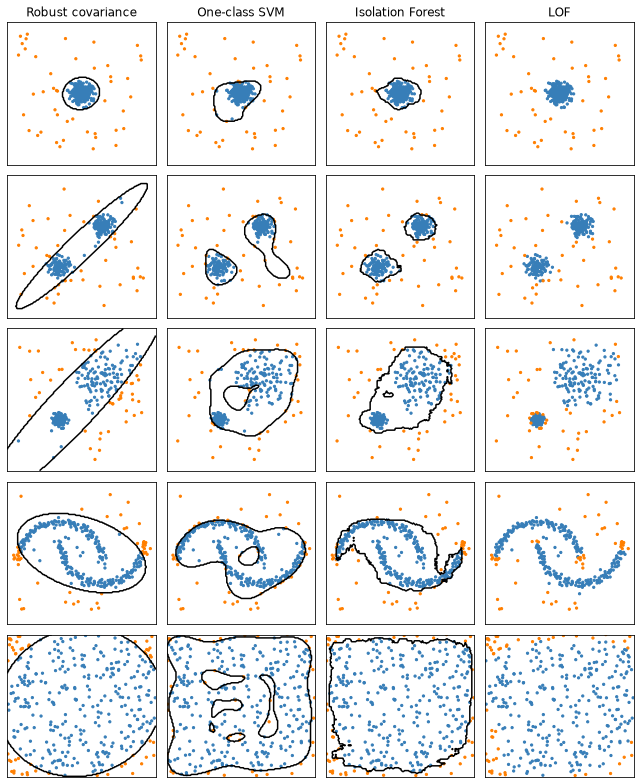

In [38]:
xx, yy = np.meshgrid(np.linspace(-7, 7, 150), np.linspace(-7, 7, 150))
rng_toy = np.random.RandomState(42)
fig, axes = plt.subplots(len(toy), 4, figsize=(9, 11))
for r, data in enumerate(toy):
    data = np.concatenate([data, rng_toy.uniform(low=-6, high=6, size=(n_out, 2))])
    for c, (name, det) in enumerate(detectors.items()):
        flags = det.fit_predict(data)
        if name != "LOF":
            axes[r, c].contour(xx, yy, det.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape), levels=[0], colors="black")
        axes[r, c].scatter(*data.T, s=5, color=np.array(["#ff7f00", "#377eb8"])[(flags + 1) // 2])
        axes[r, c].set(xlim=(-7, 7), ylim=(-7, 7), xticks=[], yticks=[], title=name if r == 0 else "")
plt.tight_layout()

### Evaluating a detector when some labels exist

*Following the approach of [Evaluation of outlier detection estimators](https://scikit-learn.org/stable/auto_examples/miscellaneous/plot_outlier_detection_bench.html) (scikit-learn developers, BSD-3-Clause).*

Without labels, evaluate a detector by inspecting a sample of the top-ranked rows. With a few known anomalies, treat the score as a classifier score and compute the **ROC AUC** (Session 8): the probability that a random anomaly scores higher than a random normal row. The scikit-learn benchmark does this on real data sets (network intrusions, forest cover types, house prices) and finds that different detectors win on different data and that LOF is sensitive to `n_neighbors`. It also recommends ordinal encoding of categories for Isolation Forest but one-hot encoding (and robust scaling) for LOF, because neighbour-based methods are affected by the ordering that ordinal codes imply. The next cell applies the same evaluation to the labelled Isolation Forest toy data above.

In [39]:
from sklearn.metrics import roc_auc_score

is_outlier = (y_if == -1).astype(int)
print("Isolation Forest ROC AUC:", round(roc_auc_score(is_outlier, -IsolationForest(random_state=0).fit(X_if).score_samples(X_if)), 3))
for k in [5, 20, 50, 150]:
    lof_k = LocalOutlierFactor(n_neighbors=k).fit(X_if)
    print(f"LOF n_neighbors={k:3d} ROC AUC:", round(roc_auc_score(is_outlier, -lof_k.negative_outlier_factor_), 3))

Isolation Forest ROC AUC: 0.994
LOF n_neighbors=  5 ROC AUC: 0.905
LOF n_neighbors= 20 ROC AUC: 0.996
LOF n_neighbors= 50 ROC AUC: 0.995


LOF n_neighbors=150 ROC AUC: 0.503


Both detectors rank the toy outliers well, but LOF depends strongly on `n_neighbors`: with very few neighbours it is noisy, and with a neighbourhood larger than a whole cluster (each cluster here has 120 points) it can no longer tell a sparse outlier from the edge of a cluster and its ROC AUC drops towards chance.

### Implausible Berlin listings

A platform, a city office or an analyst wants to find listings whose numbers do not add up. We use the listings with a price and a minimum stay below 90 nights (the medium-term rentals of block 1 have a different kind of price), four standardised columns, and both detectors. `nlargest(3, column)` shows the top of each ranking.

In [40]:
lat0, lon0 = 52.5219, 13.4132                                   # Alexanderplatz
listings["north_km"] = (listings["latitude"] - lat0) * 111.2
listings["east_km"] = (listings["longitude"] - lon0) * 111.2 * np.cos(np.radians(lat0))
listings["km_centre"] = np.hypot(listings["north_km"], listings["east_km"])
short = listings[listings["price"].notna() & (listings["minimum_nights"] < 90)].reset_index(drop=True)
short["log_price"] = np.log(short["price"])
short["log_min_nights"] = np.log(short["minimum_nights"])
Zs = StandardScaler().fit_transform(short[["log_price", "accommodates", "log_min_nights", "km_centre"]])
short["iso"] = -IsolationForest(random_state=0).fit(Zs).score_samples(Zs)
short["lof"] = -LocalOutlierFactor(n_neighbors=20).fit(Zs).negative_outlier_factor_
show = ["property_type", "accommodates", "price", "minimum_nights", "km_centre"]
print(len(short), "short-stay listings")
print(short.nlargest(3, "iso")[show + ["iso"]].round(2))
print(short.nlargest(3, "lof")[show + ["lof"]].round(2))

5507 short-stay listings
     property_type  accommodates   price  minimum_nights  km_centre   iso
3765     Houseboat            16  4458.0             1.0      22.45  0.76
4391   Entire home            16  2296.0             1.0      21.07  0.75
4651     Houseboat            12  2270.4             1.0      22.43  0.74
                    property_type  accommodates    price  minimum_nights  km_centre   lof
2796           Entire rental unit             2    41.87            60.0       6.19  2.71
597   Private room in rental unit             1    14.09            85.0      13.34  2.60
5454                  Entire home             5  7999.20             1.0      15.60  2.54


Isolation Forest ranks listings at the *edge* of the data first: large houses or houseboats for many guests at high prices far from the centre. They are rare, but not necessarily wrong. LOF finds listings that do not fit their *neighbours*, such as a two-month minimum stay among short stays, a cheap room let for months far out, or a five-guest home at a price of several thousand euros.

A sharper check states what "implausible" means: **the price compared with the price expected for the size, room type and location**. The expected price comes from a regression model (Sessions 6 and 10). Each listing's prediction is made by a model that did not see that listing (`cross_val_predict`), so a listing cannot explain away its own price. The ratio actual / expected is 1 for a typical listing.

In [41]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import KFold, cross_val_predict

Xr = pd.get_dummies(short[["accommodates", "bedrooms", "east_km", "north_km", "room_type"]], dtype=float)
expected = cross_val_predict(HistGradientBoostingRegressor(random_state=0), Xr, short["log_price"],
                             cv=KFold(5, shuffle=True, random_state=0))
short["ratio"] = np.exp(short["log_price"] - expected)
print("ratio quantiles 1 / 25 / 50 / 75 / 99 %:", short["ratio"].quantile([0.01, 0.25, 0.5, 0.75, 0.99]).round(2).to_list())
print("listings off by a factor of 3 or more:", ((short["ratio"] > 3) | (short["ratio"] < 1 / 3)).sum())
print(short.nlargest(3, "ratio")[show + ["number_of_reviews", "ratio"]].round(2))
print(short.nsmallest(3, "ratio")[show + ["number_of_reviews", "ratio"]].round(2))

ratio quantiles 1 / 25 / 50 / 75 / 99 %: [0.38, 0.8, 1.0, 1.24, 2.93]
listings off by a factor of 3 or more: 98
                    property_type  accommodates     price  minimum_nights  km_centre  number_of_reviews  ratio
3260                  Entire loft             7  10025.00             2.0      14.50                 68  53.11
5454                  Entire home             5   7999.20             1.0      15.60                  0  33.19
1157  Private room in rental unit             2    953.33             3.0       2.47                 67   9.13
                    property_type  accommodates  price  minimum_nights  km_centre  number_of_reviews  ratio
1485           Entire rental unit             2  18.85             2.0       4.38                 24   0.08
47    Private room in rental unit             2   9.03            25.0       3.59                310   0.09
297            Entire rental unit             2  14.80            28.0       2.41                152   0.10


At the top are prices of several thousand euros a night for ordinary homes, tens of times the expected price: placeholder prices that block the calendar, or typing errors, not market prices. At the bottom are flats and rooms near the centre at about a tenth of the expected price: probably monthly rates entered as nightly prices, or discounts the scraper read as the price.

**Predict.** How many of the top 100 Isolation Forest listings will also be among the 100 listings with the most extreme price ratio?

In [42]:
top_iso = set(short.nlargest(100, "iso").index)
top_ratio = set(short.assign(dev=np.abs(np.log(short["ratio"]))).nlargest(100, "dev").index)
print("overlap of the two top-100 lists:", len(top_iso & top_ratio))

overlap of the two top-100 lists: 27


The lists overlap little: a generic detector looks for *rare* listings, the domain check for *inconsistent* ones. The domain check is easier to explain and act on ("price 50 times the expected price; please check"). A person then checks the listing page, and the price model of Session 10 excludes or caps such rows.

> **Note.** The contamination parameter is a guess, not a result: `contamination=0.01` simply flags the top 1 % of scores. Prefer to look at the ranked scores and choose a threshold with the people who will review the flags (how many can they check per week?). And anomalous is not the same as wrong: deleting flagged rows without inspection removes exactly the cases that may matter most.

Where anomaly detection is used: fraud screening alongside supervised fraud models (new fraud patterns have no labels yet), condition monitoring of machines from sensor readings, and IT operations, where unusual combinations of latency, error rate and traffic raise alerts for an engineer.

> 📖 **Read more:** [extras/19-anomaly-detection-compared.ipynb](extras/19-anomaly-detection-compared.ipynb), [extras/20-isolation-forest.ipynb](extras/20-isolation-forest.ipynb), [extras/21-local-outlier-factor.ipynb](extras/21-local-outlier-factor.ipynb) and [extras/22-outlier-detection-benchmark.ipynb](extras/22-outlier-detection-benchmark.ipynb) (scikit-learn gallery); the benchmark downloads its data sets on first run. Hyndman (2026), *That's Weird: Anomaly Detection Using R*, https://otexts.com/weird/, treats the statistics of anomaly scores in depth.

## Clusters and components as features

Unsupervised outputs can be inputs to a supervised model:

- **cluster membership** as a categorical feature, or the **distances to each centroid** (`KMeans.transform`), which are numeric and smoother;
- **principal component scores** instead of, or in addition to, many correlated columns (principal component regression);
- **anomaly scores** as a feature ("how unusual is this transaction?");
- **aggregates at another level**, such as the cluster of a whole group of rows (all listings of a host) attached to each row.

Like scaling, these are **preparation steps that are fitted**. They belong inside the pipeline and are fitted on the training folds only; clusters computed on all rows, including the test rows, leak information.

```mermaid
flowchart LR
    T["Training rows"] --> S["Scaler.fit"]
    S --> K["KMeans.fit<br/>(or PCA.fit)"]
    K --> F["Original features +<br/>centroid distances"]
    F --> M["Model.fit"]
    V["Validation rows"] -.->|"transform only"| S
    S -.-> K
    K -.-> F
    F -.->|"predict"| M
```

A cluster or component can summarise many columns in a way a model would otherwise have to learn from scratch, which helps simple models and small data. With flexible models and enough data the gain is often small. The only way to know is to compare with and without under cross-validation.

### Centroid distances and components in the Telco churn model

We start with the Telco churn model and a logistic regression. `make_union(FunctionTransformer(), KMeans(...))` keeps the original columns and appends the eight centroid distances; because it sits inside the pipeline, k-means is refitted in every fold.

In [43]:
from sklearn.cluster import KMeans
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import FunctionTransformer, make_union

url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
telco = pd.read_csv(url)
telco["TotalCharges"] = pd.to_numeric(telco["TotalCharges"], errors="coerce")
telco = telco.dropna(subset=["TotalCharges"])
tcols, y = ["tenure", "MonthlyCharges", "TotalCharges"], (telco["Churn"] == "Yes").astype(int)
models = {"3 columns": make_pipeline(StandardScaler(), LogisticRegression()),
          "3 columns + 8 centroid distances": make_pipeline(StandardScaler(), make_union(
              FunctionTransformer(), KMeans(n_clusters=8, n_init=10, random_state=0)), LogisticRegression(max_iter=1000)),
          "2 principal components": make_pipeline(StandardScaler(), PCA(n_components=2), LogisticRegression())}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
for name, model in models.items():
    print(f"{name:34s} ROC AUC {cross_val_score(model, telco[tcols], y, cv=cv, scoring='roc_auc').mean():.3f}")

3 columns                          ROC AUC 0.809


3 columns + 8 centroid distances   ROC AUC 0.814
2 principal components             ROC AUC 0.807


The centroid distances let the linear model bend its boundary and gain a little ROC AUC, an effect of the size of the fold-to-fold noise. Two components lose almost nothing compared with three correlated columns.

### Scaling before PCA inside a classifier

*Adapted from [Importance of Feature Scaling](https://scikit-learn.org/stable/auto_examples/preprocessing/plot_scaling_importance.html) (scikit-learn developers, BSD-3-Clause).*

The last part of the scikit-learn example puts two principal components into a logistic regression for the wine cultivars, once without and once with standardisation before the PCA. `LogisticRegressionCV` also tunes the regularisation strength C by cross-validation.

In [44]:
from sklearn.linear_model import LogisticRegressionCV
from sklearn.metrics import accuracy_score, log_loss

Xw_train, Xw_test, yw_train, yw_test = train_test_split(wine.data, wine.target, test_size=0.30, random_state=42)
Cs = np.logspace(-5, 5, 20)
for name, steps in [("unscaled PCA", [PCA(n_components=2)]), ("standardised + PCA", [StandardScaler(), PCA(n_components=2)])]:
    clf = make_pipeline(*steps, LogisticRegressionCV(Cs=Cs, l1_ratios=(0,), scoring="neg_log_loss", use_legacy_attributes=False, max_iter=5000)).fit(Xw_train, yw_train)
    print(f"{name:20s} C={float(np.ravel(clf[-1].C_)[0]):.4g}  accuracy {accuracy_score(yw_test, clf.predict(Xw_test)):.1%}"
          f"  log-loss {log_loss(yw_test, clf.predict_proba(Xw_test)):.3f}")

unscaled PCA         C=1e-05  accuracy 74.1%  log-loss 0.497
standardised + PCA   C=6.158  accuracy 96.3%  log-loss 0.074


With standardisation the two components separate the cultivars and the classifier is far more accurate. Here all variables are expected to be informative; if the small-scale variables were pure noise, scaling could instead *increase* overfitting, because noisy features would count more after scaling.

### Location clusters in a Berlin price model

A case where a cluster feature has a plausible job is **location in a price model**. A gradient-boosting model for the log price of the short-stay listings (as in Session 10) knows the district, but Berlin's twelve districts are large and mixed. k-means on the coordinates gives 20 **location clusters**, compact areas of similar size; their centroid distances describe where a listing is more finely than the district. The baseline is the district alone, the competitor the raw coordinates, which a tree can split on directly. Hosts with many similar listings would make random folds optimistic (Session 7), so the folds are grouped by host with `GroupKFold`.

In [45]:
from sklearn.compose import make_column_transformer
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import OrdinalEncoder


def price_model(location=None):
    parts = [(OrdinalEncoder(), ["room_type", "district"]), ("passthrough", ["accommodates", "bedrooms", "minimum_nights"])]
    if location == "clusters":                                   # 20 centroid distances, refitted per fold
        parts.append((KMeans(n_clusters=20, n_init=10, random_state=0), ["east_km", "north_km"]))
    if location == "coordinates":
        parts.append(("passthrough", ["east_km", "north_km"]))
    return make_pipeline(make_column_transformer(*parts), HistGradientBoostingRegressor(categorical_features=[0, 1], random_state=0))

**Predict.** Will the location clusters beat the raw coordinates for a gradient-boosting model?

In [46]:
for name, location in [("district only", None), ("+ 20 location-cluster distances", "clusters"), ("+ raw coordinates", "coordinates")]:
    mae = -cross_val_score(price_model(location), short, short["log_price"], groups=short["host_id"],
                           cv=GroupKFold(n_splits=5), scoring="neg_mean_absolute_error")
    print(f"{name:32s} MAE (log) {mae.mean():.3f} +/- {mae.std():.3f}")

district only                    MAE (log) 0.302 +/- 0.009


+ 20 location-cluster distances  MAE (log) 0.294 +/- 0.012


+ raw coordinates                MAE (log) 0.294 +/- 0.012


An MAE of about 0.3 on the log scale means a typical prediction is off by a factor of about e^0.3 ≈ 1.35. The location clusters reduce the error a little, by about the size of the fold-to-fold spread, but the raw coordinates do just as well: a tree can find the expensive areas itself when it gets the coordinates. Cluster features earn their place where the model cannot use the raw information (a linear model cannot use latitude and longitude well), where a summary must be explained to people ("listings in location cluster 7"), or where the same areas are reused in many analyses.

> **Note.** A small gain in one split is not evidence. Report the spread across folds (Session 7) and compare with the obvious alternative, here raw coordinates. Where k-means features are known to help: Coates and Ng (2012) showed that centroid distances of k-means on image patches give competitive features for image recognition.

## Check your understanding

1. Two standardised columns have correlation 0. What are the eigenvalues of their correlation matrix, and how much variance does PC1 explain?
2. In the wine data PC1 explains about a third of the variance after standardising and almost all of it without. Which result is misleading, and why?
3. In a t-SNE map, group A is twice as large as group B and far away from it. Which of these two observations can you report?
4. Why does Isolation Forest miss the 192 cm / 55 kg person while LOF finds it?
5. A colleague sets `contamination=0.05` and reports "5 % of the Berlin listings are fake". What is wrong with this statement?

## Exercises (30 min)

Work in pairs. The lecturer picks which exercises to set; there are more than fit into 30 minutes. Paper and Predict tasks are answered in the markdown cell below the task, before any code is run. The code exercises use `listings`, `short`, `A` and `scores_a` from the cells above. The setup cell below rebuilds the six standardised listing features `Z6` of block 1 (setup, not the point of the exercises).

In [47]:
# Setup: the six standardised features of block 1 for the listings with a price
d = listings.dropna(subset=["price", "minimum_nights"]).reset_index(drop=True)
features6 = pd.DataFrame({
    "log_price": np.log(d["price"]), "guests": d["accommodates"],
    "log_min_nights": np.log(d["minimum_nights"]), "availability_365": d["availability_365"],
    "log_reviews_ltm": np.log1p(d["number_of_reviews_ltm"]), "km_centre": d["km_centre"],
})
Z6 = StandardScaler().fit_transform(features6)
print(Z6.shape)

(6753, 6)


### 2.1 · Height in cm and in inches

*Paper · 5 min*

> A table has two columns: the height of each person in centimetres and the same height in inches. How many principal components are needed to describe it?

*Source:* original exercise for this course; background: [Principal component analysis, Wikipedia](https://en.wikipedia.org/wiki/Principal_component_analysis)

*Your answer:*

### 2.2 · The empty middle of a hypercube

*Paper · 5 min*

> In 100 dimensions, what share of a unit cube lies within 0.05 of a face? What does this mean for distances between points in high dimensions?

*Source:* [Curse of dimensionality, Wikipedia](https://en.wikipedia.org/wiki/Curse_of_dimensionality)

*Your answer:*

### 2.3 · Isolate the outlier

*Class · 10 min*

> The lecturer draws a line of points on the board, one of them far from the others. Students take turns making random cuts between the smallest and the largest point. How many cuts does it take to isolate the extreme point, and how many to isolate a point in the dense middle?

*Source:* [Liu, Ting & Zhou (2008), "Isolation forest", ICDM](https://doi.org/10.1109/ICDM.2008.17)

*Your answer:*

### 2.4 · PCA of the six listing features

*Code · 15 min*

> Run `PCA()` on the standardised six features `Z6`.
>
> 1. How much variance do the components explain, and how many do you need for 80 %?
> 2. Show the loadings of PC1 and PC2 as a table with the feature names. Give each component a name.
> 3. Plot the listings on PC1 and PC2, coloured by room type. Which room types separate?

*Source:* original exercise for this course; background: [scikit-learn: Principal component analysis](https://scikit-learn.org/stable/modules/decomposition.html#pca)

### 2.5 · How stable is a LOF ranking?

*Code · 10 min*

> Use the standardised four columns of the short-stay listings (`Zs` above). Rank the listings with `LocalOutlierFactor` for `n_neighbors` = 5, 20 and 100 (score: `-negative_outlier_factor_`). How many of the top 20 listings do the three rankings share? What does that mean for a list sent to a city office?

*Source:* original exercise for this course; background: [Breunig et al. (2000), "LOF: identifying density-based local outliers", SIGMOD](https://doi.org/10.1145/342009.335388)

### 2.6 · Do location clusters help a linear model?

*Pairs · 20 min*

> The notebook shows that 20 k-means location clusters lower the error of a gradient-boosting price model only a little, and raw coordinates do as well. Repeat the comparison with a linear model: one-hot encode room type and district, keep guests, bedrooms and minimum nights, impute missing values, and fit `Ridge` on the log price of the short-stay listings (`short`), with `GroupKFold(5)` grouped by `host_id`. Compare three variants: no location, plus the distances to 20 k-means location clusters (fitted inside the pipeline), plus raw coordinates. Do the clusters help more here, and why?

*Source:* original exercise for this course; background: [scikit-learn: Pipelines and composite estimators](https://scikit-learn.org/stable/modules/compose.html)

### 2.7 · Amenities as a seventh clustering feature

*Code · 15 min · Stretch*

> *Stretch:* Add the amenity score PC1 (`scores_a[:, 0]`, one value per row of `listings`) to the six features of the listings with a price (`features6`; match rows by `d["id"]`) as a seventh column, standardise, and run k-means with five clusters. How do the clusters change compared with block 1? Which choice of features answers the question "what kinds of offers exist?" better?

*Source:* original exercise for this course

## Debrief (15 min)

- **Compare** the names pairs gave to the components in 2.4 and check them against the loadings, not against the plot.
- **Typical mistakes to look for:** PCA on unscaled columns with different units; reading distances or group sizes off a t-SNE map; treating `contamination` as an estimate; k-means or the scaler fitted outside the cross-validation in 2.6; deleting flagged listings without inspection.
- **In 2.5**, ask how many listings the three LOF rankings share and what a city office should be told about the setting used.
- **Bridge to the next sessions:** Session 12 moves to time series, where rows are ordered and the split must respect time. Sessions 13 and 14 return to these tools: TF-IDF vectors of customs descriptions are reduced with `TruncatedSVD`, and text embeddings are clustered and mapped with the methods of this session.

## Further reading

- James, G., Witten, D., Hastie, T., Tibshirani, R. and Taylor, J. (2023). *An Introduction to Statistical Learning with Applications in Python*, Chapter 12.2 "Principal Components Analysis". Springer. https://www.statlearning.com/
- Géron, A. (2022). *Hands-On Machine Learning with Scikit-Learn, Keras and TensorFlow*, 3rd edition, Chapter 8 "Dimensionality Reduction" and the anomaly-detection part of Chapter 9. O'Reilly.
- VanderPlas, J. (2016). *Python Data Science Handbook*, Chapters 5.09 "In Depth: Principal Component Analysis" and 5.10 "In-Depth: Manifold Learning". O'Reilly. https://jakevdp.github.io/PythonDataScienceHandbook/
- scikit-learn developers. *User Guide: Decomposing signals in components*, *Manifold learning* and *Novelty and Outlier Detection*. https://scikit-learn.org/stable/user_guide.html
- van der Maaten, L. and Hinton, G. (2008). Visualizing data using t-SNE. *Journal of Machine Learning Research*, 9, 2579–2605. https://www.jmlr.org/papers/v9/vandermaaten08a.html
- McInnes, L., Healy, J. and Melville, J. (2018). UMAP: uniform manifold approximation and projection for dimension reduction. arXiv:1802.03426. https://arxiv.org/abs/1802.03426
- Wattenberg, M., Viégas, F. and Johnson, I. (2016). How to use t-SNE effectively. *Distill*. https://doi.org/10.23915/distill.00002
- Liu, F. T., Ting, K. M. and Zhou, Z.-H. (2008). Isolation forest. *Proceedings of the 8th IEEE International Conference on Data Mining*, 413–422. https://doi.org/10.1109/ICDM.2008.17
- Breunig, M. M., Kriegel, H.-P., Ng, R. T. and Sander, J. (2000). LOF: identifying density-based local outliers. *Proceedings of ACM SIGMOD 2000*, 93–104. https://doi.org/10.1145/342009.335388
- Coates, A. and Ng, A. Y. (2012). Learning feature representations with k-means. In *Neural Networks: Tricks of the Trade*, 2nd edition, 561–580. Springer. https://doi.org/10.1007/978-3-642-35289-8_30
- Data: IBM (2019), *Telco customer churn sample data*, https://github.com/IBM/telco-customer-churn-on-icp4d; Inside Airbnb (2026), *Berlin, snapshot of 26 June 2026*, CC BY 4.0, https://insideairbnb.com/get-the-data/; Palmer penguins (Gorman et al., 2014, CC0) and Ames housing (De Cock, 2011) as distributed by the INRIA scikit-learn MOOC.

**Extras for this block** ([provenance and licences](extras/README.md)): [10 PCA intuitions](extras/10-pca-intuitions.ipynb), [11 PCA of iris](extras/11-pca-iris.ipynb), [12 choosing components](extras/12-pca-components.ipynb), [13 preprocessing for PCA](extras/13-pca-as-preprocessing.ipynb), [14 PCA in depth](extras/14-pca-in-depth.ipynb), [15 t-SNE perplexity](extras/15-tsne-perplexity.ipynb), [16 manifold learning](extras/16-manifold-learning.ipynb), [17 manifold methods compared](extras/17-manifold-methods-compared.ipynb), [18 UMAP parameters](extras/18-umap-parameters.ipynb), [19 anomaly detectors compared](extras/19-anomaly-detection-compared.ipynb), [20 Isolation Forest](extras/20-isolation-forest.ipynb), [21 local outlier factor](extras/21-local-outlier-factor.ipynb), [22 outlier detection benchmark](extras/22-outlier-detection-benchmark.ipynb), and the review lab [23 ISLP Chapter 12](extras/23-islp-unsupervised-lab.ipynb) (PCA of the USArrests data and matrix completion in its first half; needs the `ISLP` package).